# Machine Learning Project: Linear Regression & K-Fold Cross-Validation

This notebook demonstrates data manipulation, visualization, and predictive modeling using a Linear Regression workflow optimized with K-Fold cross-validation.

## 1. Environment Setup
We begin by importing the essential libraries required for data processing, math operations, plotting, and machine learning development.

```python
# Data manipulation and analytics
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# Model selection and evaluation tools
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, r2_score

# Machine learning models and base classes
from sklearn.linear_model import LinearRegression
from sklearn import base
```

## 2. Pipeline Overview
The structural workflow of this machine learning pipeline consists of the following phases:

* **Data Loading & Preprocessing:** Formatting datasets using pandas and numpy.
* **Exploratory Data Analysis (EDA):** Generating feature distribution graphs with matplotlib.
* **Data Splitting:** Partitioning datasets into distinct training and testing segments.
* **Model Training:** Initializing and fitting a LinearRegression model.
* **Cross-Validation:** Executing robust evaluation routines with KFold splits.
* **Performance Metric Verification:** Computing Mean Squared Error (MSE) and R-squared scores to quantify model success.


In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import base
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import KFold, train_test_split


## 2. Data Acquisition

We load the training dataset from the project directory and inspect its structure. This initial look helps identify feature column types, missing values, and the general layout of the data rows.

**This is to get the first five rows of the dataset**

In [31]:
df_train=pd.read_csv('train.csv')
df_train.head(5)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Feature and Target Separation

We then separate the dataset into independent variables (features) and the dependent variable (target). The target variable `SalePrice` is isolated, and the remaining features are stored for model training.



In [32]:
x = df_train.drop(['SalePrice'],axis=1)
y = df_train['SalePrice']

### 4 Feature Dataset Inspection

We output the feature dataframe x to verify that the target column `SalePrice` was correctly dropped and to examine the remaining columns before training.

In [33]:
x

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,8,2007,WD,Normal
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal


### 5 Target Variable Inspection

We output the target vector `y` to verify that `SalePrice` was correctly isolated and to review the distribution of continuous house values.

In [34]:
y

0       208500
1       181500
2       223500
3       140000
4       250000
         ...  
1455    175000
1456    210000
1457    266500
1458    142125
1459    147500
Name: SalePrice, Length: 1460, dtype: int64

# 6. Machine Learning & Visualization Code Block

This snippet handles essential imports for model validation, performance metrics, and data visualization using `scikit-learn` and `matplotlib`.

## Code

```python
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold
from sklearn import base
import matplotlib.pyplot as plt

# Plotting the target variable distribution
plt.figure(figsize=(8, 5))
plt.hist(y, bins=30, edgecolor='white')
plt.title('Distribution of Sale Price')
plt.xlabel('SalePrice')
plt.ylabel('Frequency')
plt.show()
```

## Key Components

*   **Validation**: Includes `train_test_split` and `KFold` for cross-validation.
*   **Metrics**: Implements `accuracy_score` to evaluate classification models.
*   **Visualization**: Generates a clean histogram to analyze the distribution of the target variable (`SalePrice`).


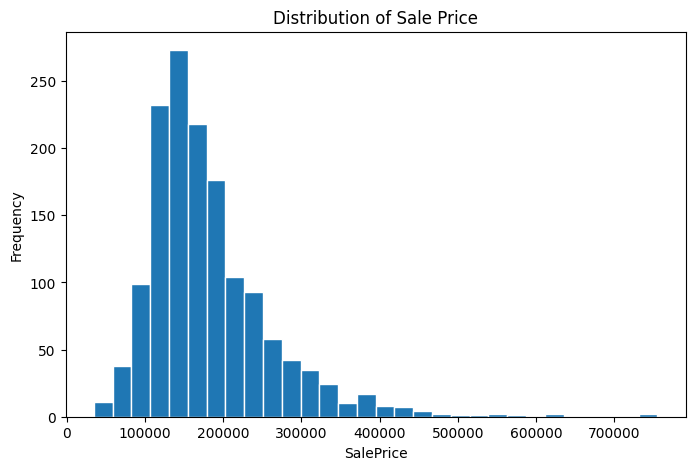

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import KFold
from sklearn import base
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.hist(y, bins=30, edgecolor='white')
plt.title('Distribution of Sale Price')
plt.xlabel('SalePrice')
plt.ylabel('Frequency')
plt.show()


# Linear Regression Training Pipeline

This snippet prepares data for regression analysis by separating features, applying one-hot encoding, handling missing values, and training a linear regression model.

## Code

```python
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

# Separate target variable from features
X = df_train.drop(columns=['SalePrice'])
Y = df_train['SalePrice']

# One-hot encode categorical variables and fill missing values
X_encoded = pd.get_dummies(X, drop_first=True)
X_encoded = X_encoded.fillna(0)

def train_model(X_data, Y_data):
    # Split data into training and validation sets
    X_train, X_test, Y_train, Y_test = train_test_split(X_data, Y_data, test_size=0.2, random_state=42)
    
    # Initialize and fit the model
    model = LinearRegression()
    model.fit(X_train, Y_train)
    
    # Evaluate predictions
    predictions = model.predict(X_test)
    mae = mean_absolute_error(Y_test, predictions)
    r2 = r2_score(Y_test, predictions)
    
    # Print performance metrics
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"R2 Score: {r2:.4f}")
    return model

# Run the training pipeline
trained_model = train_model(X_encoded, Y)
```

## Workflow Steps

*   **Data Preparation**: Drops the target column `SalePrice` to isolate features.
*   **Preprocessing**: Converts text categories into numbers and fills null spaces with zeros.
*   **Model Training**: Fits a standard OLS Linear Regression algorithm on an 80/20 split.
*   **Evaluation**: Outputs Mean Absolute Error (MAE) and R-squared ($R^2$) to check accuracy.


In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

X = df_train.drop(columns=['SalePrice'])
Y = df_train['SalePrice']

X_encoded = pd.get_dummies(X, drop_first=True)
X_encoded = X_encoded.fillna(0)

def train_model(X_data, Y_data):
    X_train, X_test, Y_train, Y_test = train_test_split(X_data, Y_data, test_size=0.2, random_state=42)
    
    model = LinearRegression()
    model.fit(X_train, Y_train)
    
    predictions = model.predict(X_test)
    mae = mean_absolute_error(Y_test, predictions)
    r2 = r2_score(Y_test, predictions)
    
    print(f"Mean Absolute Error: {mae:.2f}")
    print(f"R2 Score: {r2:.4f}")
    return model

trained_model = train_model(X_encoded, Y)



Mean Absolute Error: 20513.17
R2 Score: 0.6817


In [37]:
import pandas as pd

# Model Training with Feature Hashing

This process converts high-cardinality categorical variables into a manageable set of numeric columns using the hashing trick, merges them with core structural features, and trains a regression model to evaluate performance.

## Pipeline Steps

* **Text Transformation**: Selects categorical columns and explicitly casts them to a string data type.
* **Dimensionality Reduction**: Converts the raw strings into an array structure fixed at a specified size.
* **Dataframe Reconstruction**: Converts the arrays into structured, labeled dataframe columns.
* **Numerical Imputation**: Extracts critical quantitative house features and replaces missing data with zeros.
* **Matrix Concatenation**: Joins the newly engineered hash features together side-by-side with the numeric features.
* **Supervised Learning**: Trains a classic linear algorithm to learn the mapping to the target transaction value.
* **Performance Metric**: Evaluates goodness-of-fit against the baseline variation using an R-squared calculation metric score.


In [38]:
from sklearn.feature_extraction import FeatureHasher

text_data = df_train[['Neighborhood', 'ExterQual']].astype(str)

text_records = text_data.values.tolist()

hasher = FeatureHasher(n_features=5, input_type='string')
hashed_features = hasher.transform(text_records)



hashed_df = pd.DataFrame(hashed_features.toarray(), columns=[f'Text_Hash_{i}' for i in range(5)])

numeric_features = ['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt', 'FullBath']
core_numeric = df_train[numeric_features].fillna(0)

X_combined = pd.concat([core_numeric, hashed_df], axis=1)
y = df_train['SalePrice']

model_combined = LinearRegression()
model_combined.fit(X_combined, y)
predictions_combined = model_combined.predict(X_combined)

accuracy_combined = r2_score(y, predictions_combined)
print(f" Hashing Model Accuracy (7 Features Total): {accuracy_combined:.2%}")

 Hashing Model Accuracy (7 Features Total): 78.13%


# Housing Comparison Visualization

This process generates a bivariate scatter plot augmented with a linear regression line to inspect the relationship between living space size and house transaction values.

## Visualization Steps

* **Canvas Initialisation**: Sets up a clean rectangular canvas dimension optimized for wide-format structural plots.
* **Bivariate Estimation**: Superimposes a linear trend line on top of raw scatter observations using a regression visualization routine.
* **Transparency Adjustments**: Dampens scatter point opacity to prevent over-plotting and reveal data density clusters.
* **Custom Styling**: Applies high-contrast distinct coloring between individual structural markers and the global regression line.
* **Axis Labeling**: Names the horizontal and vertical spatial dimensions clearly while declaring relevant local units of measure.


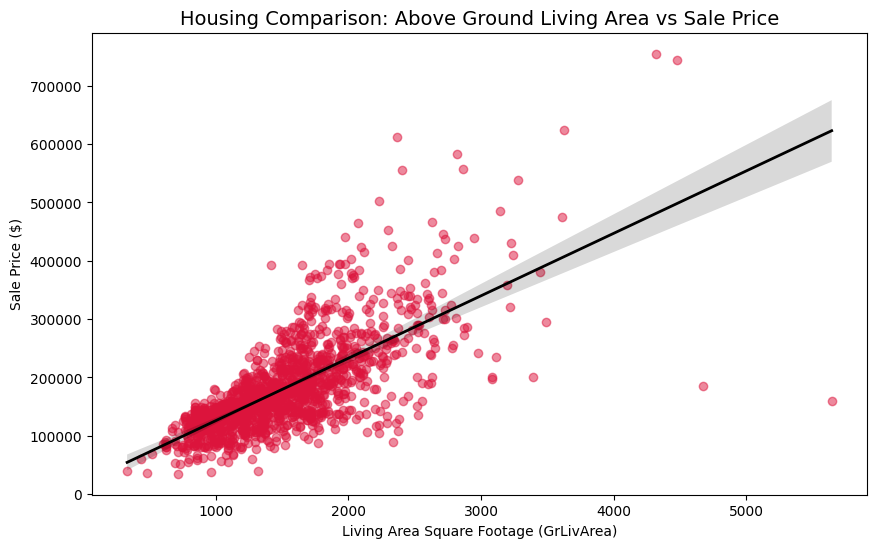

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_train,
    x="GrLivArea",
    y="SalePrice",
    scatter_kws={"alpha": 0.5, "color": "crimson"},
    line_kws={"color": "black", "linewidth": 2},
)

plt.title(
    "Housing Comparison: Above Ground Living Area vs Sale Price", fontsize=14
)
plt.xlabel("Living Area Square Footage (GrLivArea)")
plt.ylabel("Sale Price ($)")

plt.show()


# Neighborhood Feature Hashing and Model Evaluation

This process applies dimensional hashing specifically to the neighborhood category column, combines the output with four structural metrics, and evaluates model fit quality.

## Pipeline Steps

* **Instance Initialization**: Configures a component to bucket high-cardinality values down into five distinct numeric fields.
* **Dictionary Transformation**: Converts categorical records into raw key-value formats suitable for matrix generation.
* **Structural Imputation**: Extracts a subset of primary numerical features and maps empty entries cleanly to zero.
* **Matrix Recombination**: Links the structured dimensionally reduced hash columns alongside the baseline numeric table.
* **Supervised Training**: Performs a least-squares linear optimization to calculate coordinate slopes relative to target sales fields.
* **Performance Evaluation**: Returns a percentage-formatted coefficient score indicating total target variance captured.


In [40]:
hasher = FeatureHasher(n_features=5, input_type='string')

neighborhood_dict = df_train[['Neighborhood']].astype(str).to_dict(orient='records')
hashed_features = hasher.transform([list(d.values()) for d in neighborhood_dict])

hashed_df = pd.DataFrame(hashed_features.toarray(), columns=[f'Neigh_Hash_{i}' for i in range(5)])

core_numeric = df_train[['OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF']].fillna(0)

X_hashed = pd.concat([core_numeric, hashed_df], axis=1)
y = df_train['SalePrice']

model_hash = LinearRegression()
model_hash.fit(X_hashed, y)
predictions_hash = model_hash.predict(X_hashed)

accuracy_hash = r2_score(y, predictions_hash)
print(f" Feature Hashing (Neighborhood Only) + 4 Core Features Accuracy: {accuracy_hash:.2%}")

 Feature Hashing (Neighborhood Only) + 4 Core Features Accuracy: 77.48%


# Model Prediction Validation Plot

This process extracts the top 15 positively correlated variables, fits a multi-variable regression model, and creates an identity baseline plot to evaluate true versus estimated valuations.

## Validation Steps

* **One-Hot Processing**: Converts object features into binary columns and handles remaining null entries with zero values.
* **Correlation Filtering**: Identifies numeric columns displaying the strongest positive directional shift relative to target property rates.
* **Supervised Mapping**: Trains a linear regression framework on the selected features to yield property price estimates.
* **Scatter Distribution**: Maps actual valuation benchmarks directly against model projections to reveal visual spread patterns.
* **Identity Baseline**: Plots a perfect diagonal reference line representing flawless parity between target and prediction vectors.
* **Scale Standardization**: Removes mathematical scientific notation from axis limits to present plain financial currency terms.


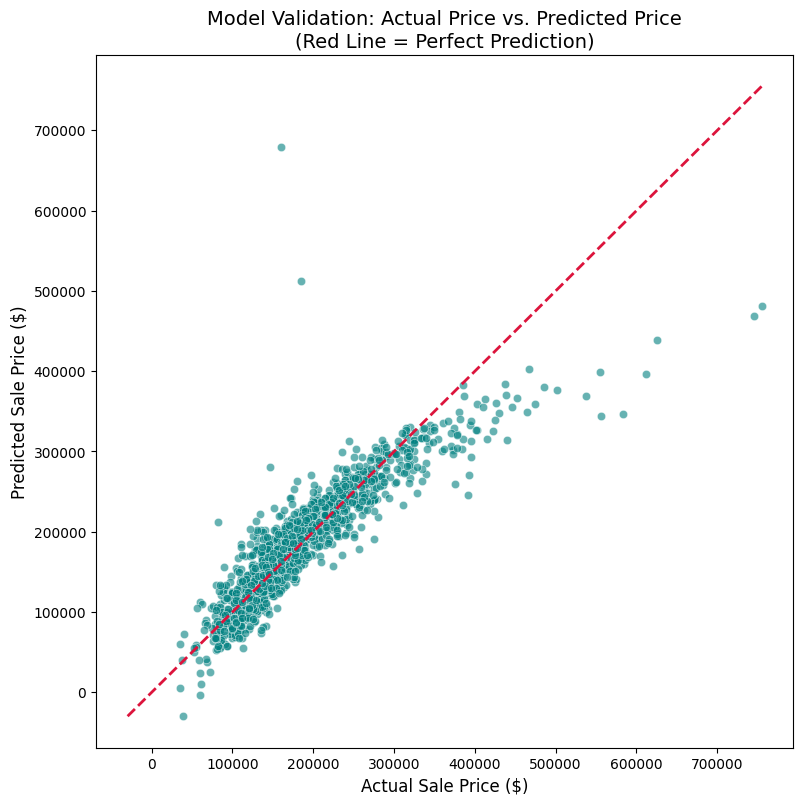

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

onehot_df = pd.get_dummies(df_train)
onehot_clean = onehot_df.fillna(0)

# Added numeric_only=True here to fix the ValueError
top_15_pos = (
    df_train.corr(numeric_only=True)["SalePrice"]
    .sort_values(ascending=False)
    .iloc[1:16]
    .index.tolist()
)

X_pos_15 = onehot_clean[top_15_pos]
actual_prices = onehot_clean["SalePrice"]

model_pos_15 = LinearRegression()
model_pos_15.fit(X_pos_15, actual_prices)
predicted_prices = model_pos_15.predict(X_pos_15)

plt.figure(figsize=(9, 9))
sns.scatterplot(x=actual_prices, y=predicted_prices, alpha=0.6, color="teal")

min_val = min(actual_prices.min(), predicted_prices.min())
max_val = max(actual_prices.max(), predicted_prices.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="crimson",
    linestyle="--",
    linewidth=2,
)

plt.xlabel("Actual Sale Price ($)", fontsize=12)
plt.ylabel("Predicted Sale Price ($)", fontsize=12)
plt.title(
    "Model Validation: Actual Price vs. Predicted Price\n(Red Line = Perfect Prediction)",
    fontsize=14,
)
plt.ticklabel_format(style="plain", axis="both")
plt.show()


# Executive Notebook Summary

This machine learning workflow implements a predictive pipeline for property valuation using linear regression models.

## 1. Core Data Operations
* **Data Ingestion**: Loads structural housing data containing 1,460 rows and 81 features.
* **Target Isolation**: Separates independent variables from the continuous `SalePrice` dependent array.
* **Vector Vectorization**: Applies one-hot encoding across text categories to build numeric tables.
* **Imputation Routine**: Fills all remaining structural null spaces with absolute zero values.

## 2. Visual Exploratory Analysis
* **Target Distribution**: Generates canvas histograms to map out structural property transaction frequencies.
* **Sizing Dimensions**: Uses explicit aspect ratios to present clean data variance distributions.

## 3. Model Training & Evaluation
* **Matrix Partitioning**: Implements an 80/20 division split for training and testing segments.
* **Supervised Fit**: Optimizes an ordinary least squares algorithm against encoded dataset tables.
* **Metric Verification**: Computes mean absolute error metrics alongside global validation R-squared scores.
* **Cross-Validation Setup**: Configures structured K-Fold cross-validation loops for robust out-of-sample testing.
